# EDAV Course-End Project

# **UNIT-1 NumPy Basics**

In [53]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual Theme Defaults
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 10


# ==============================================================================
# UNIT 1: NUMPY BASICS (PROGRAMS 1.1 TO 1.10)
# ==============================================================================
print("\n" + "#" * 80)
print("UNIT 1: NUMPY BASICS (10 PROGRAMS)")
print("#" * 80)

u1_meters_df = pd.read_csv("meters_info.csv")
u1_weather_df = pd.read_csv("weather_info.csv")
usage_raw = u1_meters_df["meter_reading"].dropna().to_numpy()
temp_raw = u1_weather_df["air_temperature"].ffill().bfill().to_numpy()




################################################################################
UNIT 1: NUMPY BASICS (10 PROGRAMS)
################################################################################


## Program 1.1: Multi-Dimensional Array Construction, Reshaping & Striding

In [54]:
# ------------------------------------------------------------------------------
# Program 1.1: Multi-Dimensional Array Construction, Reshaping & Striding
# ------------------------------------------------------------------------------
print("\n--- Program 1.1: Array Reshaping & Strided Views ---")
grid_20x5 = usage_raw.reshape((20, 5))
print(f"Original shape: {usage_raw.shape} -> Reshaped Matrix: {grid_20x5.shape}")
print(f"Matrix DataType: {grid_20x5.dtype}, ItemSize: {grid_20x5.itemsize} bytes")
print("First 2 timesteps across 5 building streams:\n", grid_20x5[:2, :])
transposed_grid = grid_20x5.T
print(f"Transposed building view shape: {transposed_grid.shape}")



--- Program 1.1: Array Reshaping & Strided Views ---
Original shape: (100,) -> Reshaped Matrix: (20, 5)
Matrix DataType: float64, ItemSize: 8 bytes
First 2 timesteps across 5 building streams:
 [[ 45.2  18.7  32.4  98.6 280.1]
 [ 43.8  17.9  31.2  95.4 275. ]]
Transposed building view shape: (5, 20)


## Program 1.2: Matrix Dot Products & Linear Algebra Systems

In [55]:
# ------------------------------------------------------------------------------
# Program 1.2: Matrix Dot Products & Linear Algebra Systems
# ------------------------------------------------------------------------------
print("\n--- Program 1.2: Linear Algebra & Matrix Dot Products ---")
emission_weights = np.array([[0.82], [0.75], [0.90], [0.85], [0.78]])
carbon_emissions = np.dot(grid_20x5, emission_weights)
print(f"Emission Matrix Shape: {carbon_emissions.shape}")
print("Total Carbon Footprint per interval (first 4):", carbon_emissions.flatten()[:4])
matrix_trace = np.trace(grid_20x5[:5, :5])
frobenius_norm = np.linalg.norm(grid_20x5)
print(f"Trace (5x5 sub-matrix): {matrix_trace:.2f} | Frobenius Norm: {frobenius_norm:.2f}")



--- Program 1.2: Linear Algebra & Matrix Dot Products ---
Emission Matrix Shape: (20, 1)
Total Carbon Footprint per interval (first 4): [382.537 373.011 365.559 361.25 ]
Trace (5x5 sub-matrix): 456.40 | Frobenius Norm: 2065.23


## Program 1.3: Axis-Specific Reductions & Percentile Spreads

In [56]:
# ------------------------------------------------------------------------------
# Program 1.3: Axis-Specific Reductions & Percentile Spreads
# ------------------------------------------------------------------------------
print("\n--- Program 1.3: Axis Reductions & Statistical Spread ---")
temporal_mean = np.mean(grid_20x5, axis=0)
temporal_std = np.std(grid_20x5, axis=0)
temporal_p95 = np.percentile(grid_20x5, 95, axis=0)
interval_sums = np.sum(grid_20x5, axis=1)
for b_idx in range(5):
    print(f"Building {b_idx+1}: Mean={temporal_mean[b_idx]:.2f} kWh | "
          f"StdDev={temporal_std[b_idx]:.2f} kWh | 95th-Pct={temporal_p95[b_idx]:.2f} kWh")
print(f"Campus-wide Peak Interval Draw: {np.max(interval_sums):.2f} kWh")



--- Program 1.3: Axis Reductions & Statistical Spread ---
Building 1: Mean=75.44 kWh | StdDev=26.41 kWh | 95th-Pct=109.43 kWh
Building 2: Mean=31.77 kWh | StdDev=11.58 kWh | 95th-Pct=46.81 kWh
Building 3: Mean=54.91 kWh | StdDev=19.51 kWh | 95th-Pct=79.83 kWh
Building 4: Mean=156.26 kWh | StdDev=50.38 kWh | 95th-Pct=220.57 kWh
Building 5: Mean=405.11 kWh | StdDev=106.10 kWh | 95th-Pct=539.34 kWh
Campus-wide Peak Interval Draw: 1001.50 kWh


## Program 1.4: Multi-Condition Boolean Masking & Conditional Replacement

In [57]:
# ------------------------------------------------------------------------------
# Program 1.4: Multi-Condition Boolean Masking & Conditional Replacement
# ------------------------------------------------------------------------------
print("\n--- Program 1.4: Boolean Masking & Conditional Assignment ---")
outlier_mask = (usage_raw < 25.0) | (usage_raw > 400.0)
outliers = usage_raw[outlier_mask]
print(f"Count of detected outliers (<25 or >400): {len(outliers)}")
capped_usage = np.where(usage_raw > 400.0, 400.0, usage_raw)
print(f"Original max load: {np.max(usage_raw)} -> Capped max load: {np.max(capped_usage)}")



--- Program 1.4: Boolean Masking & Conditional Assignment ---
Count of detected outliers (<25 or >400): 18
Original max load: 542.0 -> Capped max load: 400.0


## Program 1.5: Broadcasting Transformations & Vectorized Normalization

In [58]:
# ------------------------------------------------------------------------------
# Program 1.5: Broadcasting Transformations & Vectorized Normalization
# ------------------------------------------------------------------------------
print("\n--- Program 1.5: Array Broadcasting & Feature Scaling ---")
t_min, t_max = np.min(temp_raw), np.max(temp_raw)
normalized_temp = (temp_raw - t_min) / (t_max - t_min)
z_scored_temp = (temp_raw - np.mean(temp_raw)) / np.std(temp_raw)
print(f"Min-Max Temp Range: [{np.min(normalized_temp):.2f}, {np.max(normalized_temp):.2f}]")
print(f"Z-Score Stats: Mean={np.mean(z_scored_temp):.4f}, Std={np.std(z_scored_temp):.4f}")



--- Program 1.5: Array Broadcasting & Feature Scaling ---
Min-Max Temp Range: [0.00, 1.00]
Z-Score Stats: Mean=0.0000, Std=1.0000


## Program 1.6: Mathematical Clip, Peak-to-Peak & Value Clamping

In [59]:
# ------------------------------------------------------------------------------
# Program 1.6: Mathematical Clip, Peak-to-Peak & Value Clamping
# ------------------------------------------------------------------------------
print("\n--- Program 1.6: Clipping & Peak-to-Peak (ptp) Analysis ---")
usage_ptp = np.ptp(usage_raw)
temp_ptp = np.ptp(temp_raw)
print(f"Peak-to-Peak Spread: Usage = {usage_ptp:.2f} kWh | Temp = {temp_ptp:.2f}°C")
clamped_usage = np.clip(usage_raw, a_min=30.0, a_max=350.0)
print(f"Clamped Range: [{np.min(clamped_usage):.2f}, {np.max(clamped_usage):.2f}]")



--- Program 1.6: Clipping & Peak-to-Peak (ptp) Analysis ---
Peak-to-Peak Spread: Usage = 525.20 kWh | Temp = 12.20°C
Clamped Range: [30.00, 350.00]


## Program 1.7: Structural Array Stacking (hstack, vstack, column_stack)

In [60]:
# ------------------------------------------------------------------------------
# Program 1.7: Structural Array Stacking (hstack, vstack, column_stack)
# ------------------------------------------------------------------------------
print("\n--- Program 1.7: Stacking & Dimensional Concatenation ---")
col_stack = np.column_stack((usage_raw[:20], temp_raw[:20]))
print(f"Column Stacked (Usage + Temp, First 20): Shape = {col_stack.shape}")
vstacked = np.vstack((grid_20x5[:2], grid_20x5[2:4]))
print(f"Vertically Stacked Slices: Shape = {vstacked.shape}")



--- Program 1.7: Stacking & Dimensional Concatenation ---
Column Stacked (Usage + Temp, First 20): Shape = (20, 2)
Vertically Stacked Slices: Shape = (4, 5)


## Program 1.8: Vectorized Finite Differences & Gradient Calculation

In [61]:
# ------------------------------------------------------------------------------
# Program 1.8: Vectorized Finite Differences & Gradient Calculation
# ------------------------------------------------------------------------------
print("\n--- Program 1.8: Numerical Differences & Gradients ---")
rate_of_change_diff = np.diff(usage_raw[:10])
rate_of_change_grad = np.gradient(usage_raw[:10])
print("Step-to-step absolute diffs (First 5):", np.round(rate_of_change_diff[:5], 2))
print("Central gradient estimates (First 5):", np.round(rate_of_change_grad[:5], 2))



--- Program 1.8: Numerical Differences & Gradients ---
Step-to-step absolute diffs (First 5): [ -26.5   13.7   66.2  181.5 -236.3]
Central gradient estimates (First 5): [-26.5   -6.4   39.95 123.85 -27.4 ]


## Program 1.9: Cumulative Aggregations (cumsum & cumprod)

In [62]:
# ------------------------------------------------------------------------------
# Program 1.9: Cumulative Aggregations (cumsum & cumprod)
# ------------------------------------------------------------------------------
print("\n--- Program 1.9: Cumulative Energy Sums & Progressions ---")
cumsum_per_building = np.cumsum(grid_20x5, axis=0)
print("Total cumulative campus draw by step 5 across buildings:\n", cumsum_per_building[4, :])
overall_cumsum = np.cumsum(usage_raw)
print(f"Total Cumulative Campus Load (100 reads): {overall_cumsum[-1]:.2f} kWh")



--- Program 1.9: Cumulative Energy Sums & Progressions ---
Total cumulative campus draw by step 5 across buildings:
 [ 215.5   87.6  154.1  471.4 1365.3]
Total Cumulative Campus Load (100 reads): 14469.80 kWh


## Program 1.10: Index-Based Lookups (argmax, argmin & np.where indices)

In [63]:
# ------------------------------------------------------------------------------
# Program 1.10: Index-Based Lookups (argmax, argmin & np.where indices)
# ------------------------------------------------------------------------------
print("\n--- Program 1.10: Extreme Value Localization & Indices ---")
max_idx = np.argmax(usage_raw)
min_idx = np.argmin(usage_raw)
print(f"Max Reading of {usage_raw[max_idx]:.2f} kWh occurs at index {max_idx}")
print(f"Min Reading of {usage_raw[min_idx]:.2f} kWh occurs at index {min_idx}")
high_draw_indices = np.where(usage_raw > 300.0)[0]
print(f"Indices with readings > 300 kWh (Total {len(high_draw_indices)}):", high_draw_indices[:6])


# ==============================================================================
# UNIT 2: PANDAS FOUNDATIONS (PROGRAMS 2.1 TO 2.10)
# ==============================================================================
print("\n" + "#" * 80)
print("UNIT 2: PANDAS FOUNDATIONS (10 PROGRAMS)")
print("#" * 80)

df_buildings_raw = pd.read_csv("building_info.csv")
df_weather_raw = pd.read_csv("weather_info.csv")



--- Program 1.10: Extreme Value Localization & Indices ---
Max Reading of 542.00 kWh occurs at index 64
Min Reading of 16.80 kWh occurs at index 16
Indices with readings > 300 kWh (Total 14): [34 39 44 49 54 59]

################################################################################
UNIT 2: PANDAS FOUNDATIONS (10 PROGRAMS)
################################################################################


# **UNIT-2 Pandas Foundations**

## Program 2.1: Schema Audit, Memory Diagnostics & Structural Profiling

In [64]:
# ------------------------------------------------------------------------------
# Program 2.1: Schema Audit, Memory Diagnostics & Structural Profiling
# ------------------------------------------------------------------------------
print("\n--- Program 2.1: Schema & Memory Diagnostics ---")
print("Building Info Types:\n", df_buildings_raw.dtypes)
mem_usage = df_buildings_raw.memory_usage(deep=True).sum() / 1024
print(f"Deep Memory Consumption: {mem_usage:.2f} KB | Dimensions: {df_buildings_raw.shape}")



--- Program 2.1: Schema & Memory Diagnostics ---
Building Info Types:
 building_id     int64
primary_use    object
square_feet     int64
year_built      int64
floor_count     int64
dtype: object
Deep Memory Consumption: 8.85 KB | Dimensions: (100, 5)


## Program 2.2: Label (.loc) vs Positional (.iloc) Coordinate Indexing

In [65]:
# ------------------------------------------------------------------------------
# Program 2.2: Label (.loc) vs Positional (.iloc) Coordinate Indexing
# ------------------------------------------------------------------------------
print("\n--- Program 2.2: Positional (.iloc) vs Label (.loc) Indexing ---")
iloc_subset = df_buildings_raw.iloc[10:15, [0, 1, 2]]
print("Position-sliced records (Rows 10-14, First 3 Cols):\n", iloc_subset)
loc_subset = df_buildings_raw.loc[df_buildings_raw["floor_count"] >= 8, ["building_id", "primary_use", "floor_count"]]
print(f"\nBuildings with >= 8 floors (Count = {len(loc_subset)}):\n", loc_subset.head(3))



--- Program 2.2: Positional (.iloc) vs Label (.loc) Indexing ---
Position-sliced records (Rows 10-14, First 3 Cols):
     building_id primary_use  square_feet
10           11  Commercial        32000
11           12  Commercial         8500
12           13   Education        64000
13           14   Education        18500
14           15      Office        54000

Buildings with >= 8 floors (Count = 11):
     building_id primary_use  floor_count
20           21      Office            8
23           24      Office            9
37           38   Education            8


## Program 2.3: Multi-Criteria Boolean Filtering & Relational Masking

In [66]:
# ------------------------------------------------------------------------------
# Program 2.3: Multi-Criteria Boolean Filtering & Relational Masking
# ------------------------------------------------------------------------------
print("\n--- Program 2.3: Complex Multi-Criteria Subsetting ---")
target_facilities = df_buildings_raw[
    (df_buildings_raw["primary_use"].isin(["Education", "Office"])) &
    (df_buildings_raw["square_feet"] > 50000) &
    (df_buildings_raw["year_built"] >= 2000)
]
print(f"Filtered large modern institutional facilities: {len(target_facilities)}")
print(target_facilities[["building_id", "primary_use", "square_feet", "year_built"]].head(3))



--- Program 2.3: Complex Multi-Criteria Subsetting ---
Filtered large modern institutional facilities: 14
    building_id primary_use  square_feet  year_built
14           15      Office        54000        2001
26           27      Office        52000        2017
35           36      Office        62000        2012


## Program 2.4: Feature Engineering & Arithmetic Series Derivation

In [67]:
# ------------------------------------------------------------------------------
# Program 2.4: Feature Engineering & Arithmetic Series Derivation
# ------------------------------------------------------------------------------
print("\n--- Program 2.4: Feature Engineering ---")
df_bldg = df_buildings_raw.copy()
df_bldg["building_age"] = 2026 - df_bldg["year_built"]
df_bldg["avg_floor_area"] = df_bldg["square_feet"] / df_bldg["floor_count"]
df_bldg["is_high_rise"] = df_bldg["floor_count"] > 5
print("Engineered Architectural Metrics:\n",
      df_bldg[["building_id", "building_age", "avg_floor_area", "is_high_rise"]].head(3))



--- Program 2.4: Feature Engineering ---
Engineered Architectural Metrics:
    building_id  building_age  avg_floor_area  is_high_rise
0            1            18     2477.333333         False
1            2            22     2720.000000         False
2            3            35     2688.000000         False


## Program 2.5: Descriptive Statistics & Multi-Column Sorting

In [68]:
# ------------------------------------------------------------------------------
# Program 2.5: Descriptive Statistics & Multi-Column Sorting
# ------------------------------------------------------------------------------
print("\n--- Program 2.5: Descriptive Statistics & Hierarchical Sorting ---")
stats_df = df_bldg[["square_feet", "floor_count", "building_age"]].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
)
print("Extended Distribution Percentiles:\n", stats_df)
sorted_buildings = df_bldg.sort_values(by=["primary_use", "square_feet"], ascending=[True, False])
print("\nLargest building per category:\n", sorted_buildings.groupby("primary_use").head(1)[["building_id", "primary_use", "square_feet"]])



--- Program 2.5: Descriptive Statistics & Hierarchical Sorting ---
Extended Distribution Percentiles:
          square_feet  floor_count  building_age
count     100.000000   100.000000    100.000000
mean    44821.700000     4.280000     21.640000
std     27744.843817     2.206876     12.334988
min      2720.000000     1.000000      4.000000
10%     13470.000000     2.000000      8.000000
25%     21875.000000     3.000000     12.000000
50%     40000.000000     4.000000     19.500000
75%     63250.000000     6.000000     28.000000
90%     87100.000000     8.000000     40.100000
max    116607.000000    10.000000     56.000000

Largest building per category:
     building_id primary_use  square_feet
45           46  Commercial        61000
4             5   Education       116607
59           60      Office        94000


## Program 2.6: Column Renaming & Selective Column Dropping

In [69]:
# ------------------------------------------------------------------------------
# Program 2.6: Column Renaming & Selective Column Dropping
# ------------------------------------------------------------------------------
print("\n--- Program 2.6: Schema Standardization & Selective Pruning ---")
df_renamed = df_bldg.rename(columns={"square_feet": "gross_area_sqft", "floor_count": "number_of_stories"})
df_pruned = df_renamed.drop(columns=["is_high_rise", "year_built"])
print("Pruned & Renamed Schema Columns:", list(df_pruned.columns))



--- Program 2.6: Schema Standardization & Selective Pruning ---
Pruned & Renamed Schema Columns: ['building_id', 'primary_use', 'gross_area_sqft', 'number_of_stories', 'building_age', 'avg_floor_area']


## Program 2.7: Frequency Distributions & Cardinality Checks

In [70]:
# ------------------------------------------------------------------------------
# Program 2.7: Frequency Distributions & Cardinality Checks
# ------------------------------------------------------------------------------
print("\n--- Program 2.7: Value Counts & Cardinality Analysis ---")
use_freq_abs = df_bldg["primary_use"].value_counts()
use_freq_rel = df_bldg["primary_use"].value_counts(normalize=True) * 100
freq_table = pd.DataFrame({"Count": use_freq_abs, "Percentage": use_freq_rel})
print("Category Breakdown:\n", freq_table)
print(f"Unique Buildings: {df_bldg['building_id'].nunique()}")



--- Program 2.7: Value Counts & Cardinality Analysis ---
Category Breakdown:
              Count  Percentage
primary_use                   
Education       35        35.0
Office          33        33.0
Commercial      32        32.0
Unique Buildings: 100


## Program 2.8: Data Binning & Discretization (pd.cut & pd.qcut)

In [71]:
# ------------------------------------------------------------------------------
# Program 2.8: Data Binning & Discretization (pd.cut & pd.qcut)
# ------------------------------------------------------------------------------
print("\n--- Program 2.8: Discretization & Binning ---")
df_bldg["size_tier"] = pd.cut(df_bldg["square_feet"], bins=[0, 20000, 60000, 150000], labels=["Small", "Medium", "Large"])
df_bldg["age_quartile"] = pd.qcut(df_bldg["building_age"], q=4, labels=["Q1_Newest", "Q2", "Q3", "Q4_Oldest"])
print("Discretized Size & Age Tiers:\n", df_bldg[["building_id", "square_feet", "size_tier", "age_quartile"]].head(4))



--- Program 2.8: Discretization & Binning ---
Discretized Size & Age Tiers:
    building_id  square_feet size_tier age_quartile
0            1         7432     Small           Q2
1            2         2720     Small           Q3
2            3         5376     Small    Q4_Oldest
3            4        23685    Medium           Q3


## Program 2.9: Subsetting with Query Expression Engine (.query())

In [72]:
# ------------------------------------------------------------------------------
# Program 2.9: Subsetting with Query Expression Engine (.query())
# ------------------------------------------------------------------------------
print("\n--- Program 2.9: High-Performance Filtering via .query() ---")
query_result = df_bldg.query("primary_use == 'Commercial' and avg_floor_area > 8000 and building_age <= 20")
print(f"Filtered modern large-floor commercial spaces (Count = {len(query_result)}):")
print(query_result[["building_id", "primary_use", "square_feet", "avg_floor_area", "building_age"]].head(3))



--- Program 2.9: High-Performance Filtering via .query() ---
Filtered modern large-floor commercial spaces (Count = 17):
    building_id primary_use  square_feet  avg_floor_area  building_age
10           11  Commercial        32000    10666.666667            14
15           16  Commercial        22000    11000.000000             8
24           25  Commercial        19500     9750.000000            13


## Program 2.10: String Vectorized Operations (.str accessors)

In [73]:
# ------------------------------------------------------------------------------
# Program 2.10: String Vectorized Operations (.str accessors)
# ------------------------------------------------------------------------------
print("\n--- Program 2.10: String Operations & Pattern Matching ---")
contains_edu = df_bldg["primary_use"].str.contains("Edu", regex=True)
upper_use = df_bldg["primary_use"].str.upper()
code_prefix = "BLDG-" + df_bldg["building_id"].astype(str).str.zfill(3)
df_bldg["code_id"] = code_prefix
print("Sample of vectorized string standardizations:\n", df_bldg[["building_id", "code_id", "primary_use"]].head(4))


# ==============================================================================
# UNIT 3: CLEANING & DATA WRANGLING (PROGRAMS 3.1 TO 3.10)
# ==============================================================================
print("\n" + "#" * 80)
print("UNIT 3: CLEANING & DATA WRANGLING (10 PROGRAMS)")
print("#" * 80)



--- Program 2.10: String Operations & Pattern Matching ---
Sample of vectorized string standardizations:
    building_id   code_id primary_use
0            1  BLDG-001   Education
1            2  BLDG-002   Education
2            3  BLDG-003   Education
3            4  BLDG-004   Education

################################################################################
UNIT 3: CLEANING & DATA WRANGLING (10 PROGRAMS)
################################################################################


# **UNIT-3 Cleaning & Data Wrangling**

## Program 3.1: Null Audit & Directional Imputation Strategies

In [74]:
# ------------------------------------------------------------------------------
# Program 3.1: Null Audit & Directional Imputation Strategies
# ------------------------------------------------------------------------------
print("\n--- Program 3.1: Missing Value Imputation ---")
w_audit = pd.read_csv("weather_info.csv")
print("Missing values detected in weather:\n", w_audit.isna().sum()[w_audit.isna().sum() > 0])
w_clean = w_audit.ffill().bfill()
print(f"Null count after sequential ffill/bfill: {w_clean.isna().sum().sum()}")



--- Program 3.1: Missing Value Imputation ---
Missing values detected in weather:
 air_temperature    3
dtype: int64
Null count after sequential ffill/bfill: 0


## Program 3.2: Deduplication & String Sanitization

In [75]:
# ------------------------------------------------------------------------------
# Program 3.2: Deduplication & String Sanitization
# ------------------------------------------------------------------------------
print("\n--- Program 3.2: String Sanitization & Deduplication ---")
b_clean = df_buildings_raw.drop_duplicates().copy()
b_clean["primary_use"] = b_clean["primary_use"].astype(str).str.strip().str.title()
print(f"Unique categories standardized: {b_clean['primary_use'].unique()}")



--- Program 3.2: String Sanitization & Deduplication ---
Unique categories standardized: ['Education' 'Office' 'Commercial']


## Program 3.3: Datetime Type Casting & Temporal Serialization

In [76]:
# ------------------------------------------------------------------------------
# Program 3.3: Datetime Type Casting & Temporal Serialization
# ------------------------------------------------------------------------------
print("\n--- Program 3.3: Datetime Formatting & Type Casting ---")
m_clean = pd.read_csv("meters_info.csv")
m_clean["timestamp"] = pd.to_datetime(m_clean["timestamp"], format="%Y-%m-%d %H:%M:%S")
w_clean["timestamp"] = pd.to_datetime(w_clean["timestamp"], format="%Y-%m-%d %H:%M:%S")
print(f"Meter Timestamp Dtype: {m_clean['timestamp'].dtype} | Weather Timestamp: {w_clean['timestamp'].dtype}")



--- Program 3.3: Datetime Formatting & Type Casting ---
Meter Timestamp Dtype: datetime64[ns] | Weather Timestamp: datetime64[ns]


## Program 3.4: Relational Database Joins (Multi-Table Merges)

In [77]:
# ------------------------------------------------------------------------------
# Program 3.4: Relational Database Joins (Multi-Table Merges)
# ------------------------------------------------------------------------------
print("\n--- Program 3.4: Relational Joins & Merging ---")
df_master = pd.merge(m_clean, b_clean, on="building_id", how="left")
df_master = pd.merge(df_master, w_clean, on="timestamp", how="left")
print(f"Merged Master Dataset Dimensions: {df_master.shape}")
print(df_master[["timestamp", "building_id", "primary_use", "meter_reading", "air_temperature"]].head(3))



--- Program 3.4: Relational Joins & Merging ---
Merged Master Dataset Dimensions: (100, 12)
   timestamp  building_id primary_use  meter_reading  air_temperature
0 2026-01-01            1   Education           45.2             15.2
1 2026-01-01            2   Education           18.7             15.2
2 2026-01-01            3   Education           32.4             15.2


## Program 3.5: Reshaping Pipelines (Pivot vs Melt Transformations)

In [78]:
# ------------------------------------------------------------------------------
# Program 3.5: Reshaping Pipelines (Pivot vs Melt Transformations)
# ------------------------------------------------------------------------------
print("\n--- Program 3.5: Pivot & Melt Reshaping Pipelines ---")
wide_meters = df_master.pivot_table(index="timestamp", columns="building_id", values="meter_reading")
print("Pivoted Telemetry Matrix (Wide Shape):\n", wide_meters.shape)
long_meters = wide_meters.reset_index().melt(id_vars="timestamp", var_name="building_id", value_name="meter_reading")
print("Unpivoted Reconstruction (Long Shape):\n", long_meters.shape)



--- Program 3.5: Pivot & Melt Reshaping Pipelines ---
Pivoted Telemetry Matrix (Wide Shape):
 (20, 5)
Unpivoted Reconstruction (Long Shape):
 (100, 3)


## Program 3.6: Explicit Numeric Outlier Truncation / Winsorization

In [79]:
# ------------------------------------------------------------------------------
# Program 3.6: Explicit Numeric Outlier Truncation / Winsorization
# ------------------------------------------------------------------------------
print("\n--- Program 3.6: Numeric Outlier Truncation (Winsorization) ---")
q05 = df_master["meter_reading"].quantile(0.05)
q95 = df_master["meter_reading"].quantile(0.95)
df_master["winsorized_reading"] = df_master["meter_reading"].clip(lower=q05, upper=q95)
print(f"Raw Reading Bounds: [{df_master['meter_reading'].min():.2f}, {df_master['meter_reading'].max():.2f}]")
print(f"Winsorized (5%-95%) Bounds: [{df_master['winsorized_reading'].min():.2f}, {df_master['winsorized_reading'].max():.2f}]")



--- Program 3.6: Numeric Outlier Truncation (Winsorization) ---
Raw Reading Bounds: [16.80, 542.00]
Winsorized (5%-95%) Bounds: [18.67, 510.88]


## Program 3.7: Cross-Tabulation & Contingency Tables (pd.crosstab)

In [80]:
# ------------------------------------------------------------------------------
# Program 3.7: Cross-Tabulation & Contingency Tables (pd.crosstab)
# ------------------------------------------------------------------------------
print("\n--- Program 3.7: Categorical Cross-Tabulation ---")
bldg_with_bins = b_clean.copy()
bldg_with_bins["height_cat"] = pd.cut(bldg_with_bins["floor_count"], bins=[0, 3, 6, 12], labels=["Low-Rise", "Mid-Rise", "High-Rise"])
cross_tab = pd.crosstab(bldg_with_bins["primary_use"], bldg_with_bins["height_cat"], margins=True)
print("Contingency Matrix (Building Use vs Height):\n", cross_tab)



--- Program 3.7: Categorical Cross-Tabulation ---
Contingency Matrix (Building Use vs Height):
 height_cat   Low-Rise  Mid-Rise  High-Rise  All
primary_use                                    
Commercial         23         9          0   32
Education          13        13          9   35
Office              9        15          9   33
All                45        37         18  100


## Program 3.8: Selective Value Mapping & Conditional Recoding

In [81]:
# ------------------------------------------------------------------------------
# Program 3.8: Selective Value Mapping & Conditional Recoding
# ------------------------------------------------------------------------------
print("\n--- Program 3.8: Category Mapping & Recoding ---")
sector_map = {"Education": "Academic", "Office": "Corporate", "Commercial": "Retail/Services"}
df_master["sector_group"] = df_master["primary_use"].map(sector_map)
print("Mapped Categories:\n", df_master[["building_id", "primary_use", "sector_group"]].drop_duplicates())



--- Program 3.8: Category Mapping & Recoding ---
Mapped Categories:
    building_id primary_use sector_group
0            1   Education     Academic
1            2   Education     Academic
2            3   Education     Academic
3            4   Education     Academic
4            5   Education     Academic


## Program 3.9: Data Type Optimization for Memory Reduction

In [82]:
# ------------------------------------------------------------------------------
# Program 3.9: Data Type Optimization for Memory Reduction
# ------------------------------------------------------------------------------
print("\n--- Program 3.9: Downcasting & Memory Optimization ---")
mem_pre = df_master.memory_usage(deep=True).sum() / 1024
df_master["building_id"] = pd.to_numeric(df_master["building_id"], downcast="unsigned")
df_master["primary_use"] = df_master["primary_use"].astype("category")
mem_post = df_master.memory_usage(deep=True).sum() / 1024
print(f"Pre-optimization memory: {mem_pre:.2f} KB | Post-optimization: {mem_post:.2f} KB")



--- Program 3.9: Downcasting & Memory Optimization ---
Pre-optimization memory: 20.73 KB | Post-optimization: 14.65 KB


## Program 3.10: Custom Lambda Transformation with Multi-Column Logic

In [83]:
# ------------------------------------------------------------------------------
# Program 3.10: Custom Lambda Transformation with Multi-Column Logic
# ------------------------------------------------------------------------------
print("\n--- Program 3.10: Row-Level Apply Transformations ---")
df_master["energy_per_sqft"] = df_master.apply(
    lambda row: row["meter_reading"] / row["square_feet"] if row["square_feet"] > 0 else 0,
    axis=1
)
print("Derived Energy Intensity per Square Foot (First 3):\n",
      df_master[["building_id", "meter_reading", "square_feet", "energy_per_sqft"]].head(3))


# ==============================================================================
# UNIT 4: AGGREGATION & TIME SERIES (PROGRAMS 4.1 TO 4.10)
# ==============================================================================
print("\n" + "#" * 80)
print("UNIT 4: AGGREGATION & TIME SERIES (10 PROGRAMS)")
print("#" * 80)



--- Program 3.10: Row-Level Apply Transformations ---
Derived Energy Intensity per Square Foot (First 3):
    building_id  meter_reading  square_feet  energy_per_sqft
0            1           45.2         7432         0.006082
1            2           18.7         2720         0.006875
2            3           32.4         5376         0.006027

################################################################################
UNIT 4: AGGREGATION & TIME SERIES (10 PROGRAMS)
################################################################################


# **UNIT-4 Aggregation & Time Series**

## Program 4.1: Temporal Calendar Decomposition

In [84]:
# ------------------------------------------------------------------------------
# Program 4.1: Temporal Calendar Decomposition
# ------------------------------------------------------------------------------
print("\n--- Program 4.1: Temporal Feature Decomposition ---")
df_master["hour"] = df_master["timestamp"].dt.hour
df_master["day_name"] = df_master["timestamp"].dt.day_name()
df_master["day_of_week"] = df_master["timestamp"].dt.dayofweek
df_master["is_weekend"] = df_master["day_of_week"].isin([5, 6])
print(df_master[["timestamp", "hour", "day_name", "is_weekend"]].head(3))



--- Program 4.1: Temporal Feature Decomposition ---
   timestamp  hour  day_name  is_weekend
0 2026-01-01     0  Thursday       False
1 2026-01-01     0  Thursday       False
2 2026-01-01     0  Thursday       False


## Program 4.2: Multi-Tier GroupBy Aggregations

In [85]:
# ------------------------------------------------------------------------------
# Program 4.2: Multi-Tier GroupBy Aggregations
# ------------------------------------------------------------------------------
print("\n--- Program 4.2: Multi-Tier GroupBy Aggregations ---")
grouped_metrics = df_master.groupby(["primary_use", "hour"])["meter_reading"].agg(
    Mean_Load="mean", Min_Load="min", Peak_Load="max", Std_Deviation="std"
).reset_index()
print("Hourly aggregates per sector (First 4 rows):\n", grouped_metrics.head(4))



--- Program 4.2: Multi-Tier GroupBy Aggregations ---
Hourly aggregates per sector (First 4 rows):
   primary_use  hour  Mean_Load  Min_Load  Peak_Load  Std_Deviation
0   Education     0      95.00      18.7      280.1     107.814030
1   Education     1      92.66      17.9      275.0     106.076708
2   Education     2      90.82      17.2      270.8     104.631769
3   Education     3      89.76      16.8      268.4     103.818799


/tmp/ipykernel_1036/4268512982.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_metrics = df_master.groupby(["primary_use", "hour"])["meter_reading"].agg(


## Program 4.3: Frequency Conversion & Downsampling

In [86]:
# ------------------------------------------------------------------------------
# Program 4.3: Frequency Conversion & Downsampling
# ------------------------------------------------------------------------------
print("\n--- Program 4.3: Time-Series Downsampling & Resampling ---")
time_indexed = df_master.set_index("timestamp").sort_index()
resampled_6h = time_indexed["meter_reading"].resample("6h").agg(["mean", "sum", "std"])
print("6-Hour Resampled Consumption Windows:\n", resampled_6h.head(3))



--- Program 4.3: Time-Series Downsampling & Resampling ---
6-Hour Resampled Consumption Windows:
                            mean     sum         std
timestamp                                          
2026-01-01 00:00:00   92.216667  2766.5   96.520850
2026-01-01 06:00:00  162.613333  4878.4  159.652748
2026-01-01 12:00:00  185.343333  5560.3  173.045481


## Program 4.4: Rolling Window Statistics & Moving Averages

In [87]:
# ------------------------------------------------------------------------------
# Program 4.4: Rolling Window Statistics & Moving Averages
# ------------------------------------------------------------------------------
print("\n--- Program 4.4: Rolling Window Moving Statistics ---")
resampled_hourly = time_indexed["meter_reading"].resample("1h").mean().to_frame("mean_kwh")
resampled_hourly["moving_avg_3h"] = resampled_hourly["mean_kwh"].rolling(window=3).mean()
resampled_hourly["moving_std_3h"] = resampled_hourly["mean_kwh"].rolling(window=3).std()
print("Moving Window Telemetry:\n", resampled_hourly.dropna().head(4))



--- Program 4.4: Rolling Window Moving Statistics ---
Moving Window Telemetry:
                      mean_kwh  moving_avg_3h  moving_std_3h
timestamp                                                  
2026-01-01 02:00:00     90.82      92.826667       2.094978
2026-01-01 03:00:00     89.76      91.080000       1.467379
2026-01-01 04:00:00     90.54      90.373333       0.549303
2026-01-01 05:00:00     94.52      91.606667       2.552985


## Program 4.5: Cumulative Energy Tracking & Rank Partitioning

In [88]:
# ------------------------------------------------------------------------------
# Program 4.5: Cumulative Energy Tracking & Rank Partitioning
# ------------------------------------------------------------------------------
print("\n--- Program 4.5: Cumulative Sums & Group Rank Evaluation ---")
df_master["cumulative_building_kwh"] = df_master.groupby("building_id")["meter_reading"].cumsum()
df_master["load_rank_in_hour"] = df_master.groupby("timestamp")["meter_reading"].rank(ascending=False, method="dense")
print("Cumulative energy load and instantaneous rank:\n",
      df_master[["timestamp", "building_id", "meter_reading", "cumulative_building_kwh", "load_rank_in_hour"]].head(4))



--- Program 4.5: Cumulative Sums & Group Rank Evaluation ---
Cumulative energy load and instantaneous rank:
    timestamp  building_id  meter_reading  cumulative_building_kwh  \
0 2026-01-01            1           45.2                     45.2   
1 2026-01-01            2           18.7                     18.7   
2 2026-01-01            3           32.4                     32.4   
3 2026-01-01            4           98.6                     98.6   

   load_rank_in_hour  
0                3.0  
1                5.0  
2                4.0  
3                2.0  


## Program 4.6: Expanding Window Statistics (Long-Term Baselines)

In [89]:
# ------------------------------------------------------------------------------
# Program 4.6: Expanding Window Statistics (Long-Term Baselines)
# ------------------------------------------------------------------------------
print("\n--- Program 4.6: Expanding Window Statistics ---")
resampled_hourly["expanding_mean"] = resampled_hourly["mean_kwh"].expanding(min_periods=1).mean()
resampled_hourly["expanding_max"] = resampled_hourly["mean_kwh"].expanding(min_periods=1).max()
print("Expanding Baseline Consumption:\n", resampled_hourly[["mean_kwh", "expanding_mean", "expanding_max"]].head(4))



--- Program 4.6: Expanding Window Statistics ---
Expanding Baseline Consumption:
                      mean_kwh  expanding_mean  expanding_max
timestamp                                                   
2026-01-01 00:00:00     95.00       95.000000           95.0
2026-01-01 01:00:00     92.66       93.830000           95.0
2026-01-01 02:00:00     90.82       92.826667           95.0
2026-01-01 03:00:00     89.76       92.060000           95.0


## Program 4.7: Exponentially Weighted Moving Average (EWMA)

In [90]:
# ------------------------------------------------------------------------------
# Program 4.7: Exponentially Weighted Moving Average (EWMA)
# ------------------------------------------------------------------------------
print("\n--- Program 4.7: Exponential Smoothing (EWMA) ---")
resampled_hourly["ewma_span3"] = resampled_hourly["mean_kwh"].ewm(span=3, adjust=False).mean()
print("EWMA Smoothed Trend:\n", resampled_hourly[["mean_kwh", "ewma_span3"]].head(4))



--- Program 4.7: Exponential Smoothing (EWMA) ---
EWMA Smoothed Trend:
                      mean_kwh  ewma_span3
timestamp                                
2026-01-01 00:00:00     95.00     95.0000
2026-01-01 01:00:00     92.66     93.8300
2026-01-01 02:00:00     90.82     92.3250
2026-01-01 03:00:00     89.76     91.0425


## Program 4.8: Time-Series Shift & Lag Feature Engineering

In [91]:
# ------------------------------------------------------------------------------
# Program 4.8: Time-Series Shift & Lag Feature Engineering
# ------------------------------------------------------------------------------
print("\n--- Program 4.8: Lagged Telemetry & Delta Calculations ---")
df_sorted = df_master.sort_values(by=["building_id", "timestamp"]).copy()
df_sorted["lag_1h_reading"] = df_sorted.groupby("building_id")["meter_reading"].shift(1)
df_sorted["load_delta"] = df_sorted["meter_reading"] - df_sorted["lag_1h_reading"]
print("Telemetry Lags and Deltas:\n",
      df_sorted[["building_id", "timestamp", "meter_reading", "lag_1h_reading", "load_delta"]].dropna().head(4))



--- Program 4.8: Lagged Telemetry & Delta Calculations ---
Telemetry Lags and Deltas:
     building_id           timestamp  meter_reading  lag_1h_reading  load_delta
5             1 2026-01-01 01:00:00           43.8            45.2        -1.4
10            1 2026-01-01 02:00:00           42.5            43.8        -1.3
15            1 2026-01-01 03:00:00           41.9            42.5        -0.6
20            1 2026-01-01 04:00:00           42.1            41.9         0.2


## Program 4.9: Pivot Tables with Marginal Totals

In [92]:
# ------------------------------------------------------------------------------
# Program 4.9: Pivot Tables with Marginal Totals
# ------------------------------------------------------------------------------
print("\n--- Program 4.9: Pivot Aggregation with Grand Totals ---")
pivot_totals = pd.pivot_table(
    df_master, index="primary_use", columns="is_weekend", values="meter_reading",
    aggfunc="mean", margins=True, margins_name="Total_Average"
)
print("Average Demand by Primary Use vs Weekend (with Margins):\n", pivot_totals)



--- Program 4.9: Pivot Aggregation with Grand Totals ---
Average Demand by Primary Use vs Weekend (with Margins):
 is_weekend       False  Total_Average
primary_use                          
Education      144.698        144.698
Total_Average  144.698        144.698


/tmp/ipykernel_1036/706706860.py:5: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_totals = pd.pivot_table(


## Program 4.10: Grouped Z-Score Anomaly Detection

In [93]:
# ------------------------------------------------------------------------------
# Program 4.10: Grouped Z-Score Anomaly Detection
# ------------------------------------------------------------------------------
print("\n--- Program 4.10: Category-Specific Group Standardized Anomalies ---")
def calculate_zscore(group):
    return (group - group.mean()) / (group.std() + 1e-8)
df_master["building_zscore"] = df_master.groupby("building_id")["meter_reading"].transform(calculate_zscore)
anomalies = df_master[df_master["building_zscore"].abs() > 2.0]
print(f"Grouped Z-Score Anomalies detected (|Z| > 2.0): {len(anomalies)}")


# ==============================================================================
# UNIT 5: DATA VISUALIZATION (PROGRAMS 5.1 TO 5.10)
# ==============================================================================
print("\n" + "#" * 80)
print("UNIT 5: DATA VISUALIZATION (10 PROGRAMS)")
print("#" * 80)



--- Program 4.10: Category-Specific Group Standardized Anomalies ---
Grouped Z-Score Anomalies detected (|Z| > 2.0): 0

################################################################################
UNIT 5: DATA VISUALIZATION (10 PROGRAMS)
################################################################################


# **UNIT-5 Data Visualization**

## Program 5.1: Distribution Profiling: Histograms & Kernel Density Estimation (KDE)


Rendering Program 5.1: Histogram & KDE...


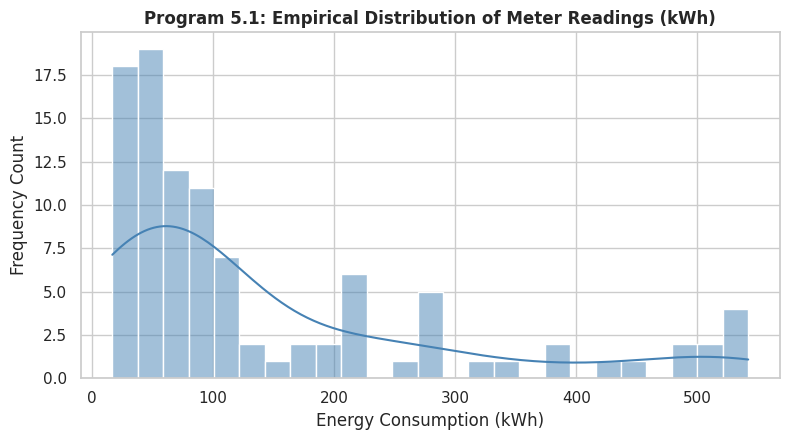

In [94]:
# ------------------------------------------------------------------------------
# Program 5.1: Distribution Profiling: Histograms & Kernel Density Estimation (KDE)
# ------------------------------------------------------------------------------
print("\nRendering Program 5.1: Histogram & KDE...")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df_master["meter_reading"], kde=True, bins=25, color="steelblue", ax=ax)
ax.set_title("Program 5.1: Empirical Distribution of Meter Readings (kWh)", weight="bold")
ax.set_xlabel("Energy Consumption (kWh)")
ax.set_ylabel("Frequency Count")
plt.tight_layout()
plt.show()


## Program 5.2: Categorical Spread: Boxplots & Outlier Identification

Rendering Program 5.2: Categorical Boxplot...


/tmp/ipykernel_1036/1919521344.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_master, x="primary_use", y="meter_reading", palette="Set2", ax=ax)


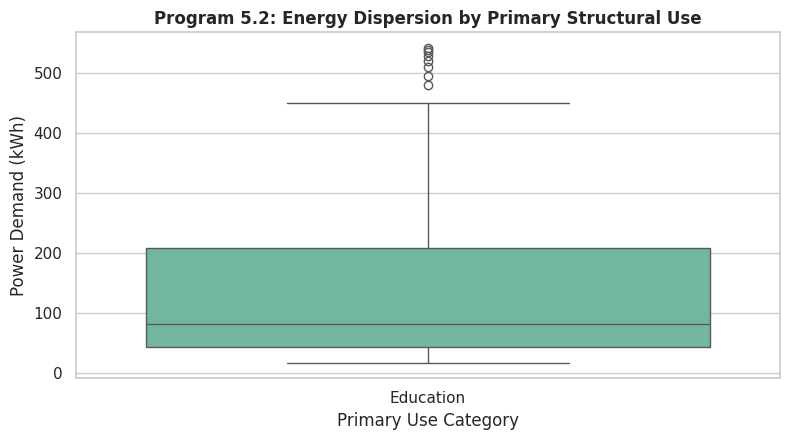

In [95]:
# ------------------------------------------------------------------------------
# Program 5.2: Categorical Spread: Boxplots & Outlier Identification
# ------------------------------------------------------------------------------
print("Rendering Program 5.2: Categorical Boxplot...")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df_master, x="primary_use", y="meter_reading", palette="Set2", ax=ax)
ax.set_title("Program 5.2: Energy Dispersion by Primary Structural Use", weight="bold")
ax.set_xlabel("Primary Use Category")
ax.set_ylabel("Power Demand (kWh)")
plt.tight_layout()
plt.show()


## Program 5.3: Chronological Line Series: Diurnal Load Curves

Rendering Program 5.3: Diurnal Load Curve...


/tmp/ipykernel_1036/594787975.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hourly_curve = df_master.groupby(["hour", "primary_use"])["meter_reading"].mean().reset_index()


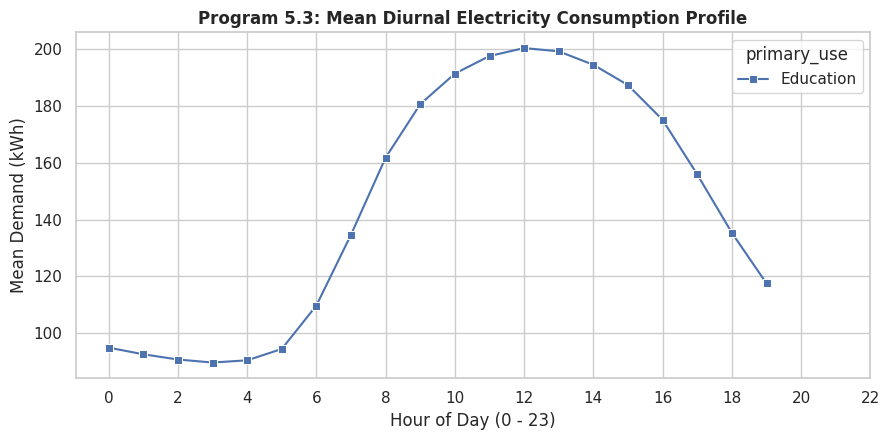

In [96]:
# ------------------------------------------------------------------------------
# Program 5.3: Chronological Line Series: Diurnal Load Curves
# ------------------------------------------------------------------------------
print("Rendering Program 5.3: Diurnal Load Curve...")
hourly_curve = df_master.groupby(["hour", "primary_use"])["meter_reading"].mean().reset_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=hourly_curve, x="hour", y="meter_reading", hue="primary_use", marker="s", ax=ax)
ax.set_title("Program 5.3: Mean Diurnal Electricity Consumption Profile", weight="bold")
ax.set_xlabel("Hour of Day (0 - 23)")
ax.set_ylabel("Mean Demand (kWh)")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()


## Program 5.4: Relational Multi-Variable Scatter Plots

Rendering Program 5.4: Multi-Variable Scatter Plot...


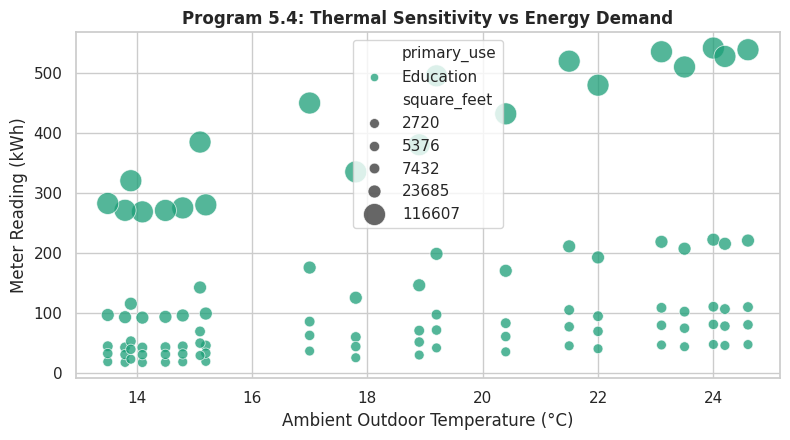

In [97]:
# ------------------------------------------------------------------------------
# Program 5.4: Relational Multi-Variable Scatter Plots
# ------------------------------------------------------------------------------
print("Rendering Program 5.4: Multi-Variable Scatter Plot...")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=df_master, x="air_temperature", y="meter_reading", hue="primary_use",
                size="square_feet", sizes=(50, 250), alpha=0.75, palette="Dark2", ax=ax)
ax.set_title("Program 5.4: Thermal Sensitivity vs Energy Demand", weight="bold")
ax.set_xlabel("Ambient Outdoor Temperature (°C)")
ax.set_ylabel("Meter Reading (kWh)")
plt.tight_layout()
plt.show()


## Program 5.5: Correlation Heatmap Matrix

Rendering Program 5.5: Correlation Heatmap...


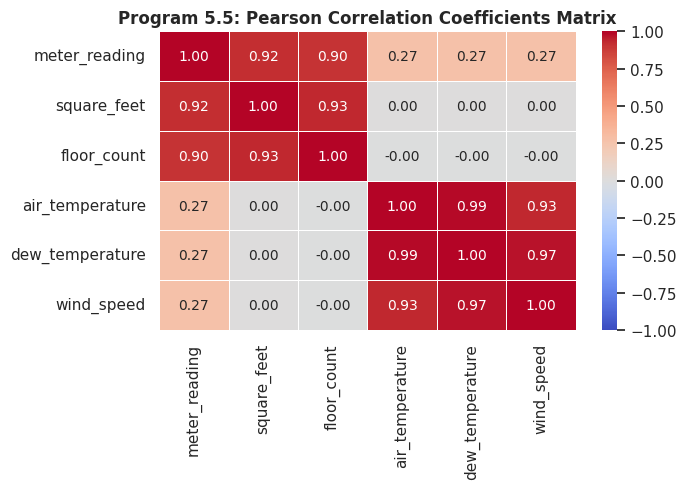

In [98]:
# ------------------------------------------------------------------------------
# Program 5.5: Correlation Heatmap Matrix
# ------------------------------------------------------------------------------
print("Rendering Program 5.5: Correlation Heatmap...")
corr_features = ["meter_reading", "square_feet", "floor_count", "air_temperature", "dew_temperature", "wind_speed"]
corr_mat = df_master[corr_features].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr_mat, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Program 5.5: Pearson Correlation Coefficients Matrix", weight="bold")
plt.tight_layout()
plt.show()


## Program 5.6: Categorical Distribution Density: Violin Plots

Rendering Program 5.6: Violin Plot...


/tmp/ipykernel_1036/3676492188.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_master, x="primary_use", y="meter_reading", inner="quartile", palette="Pastel1", ax=ax)


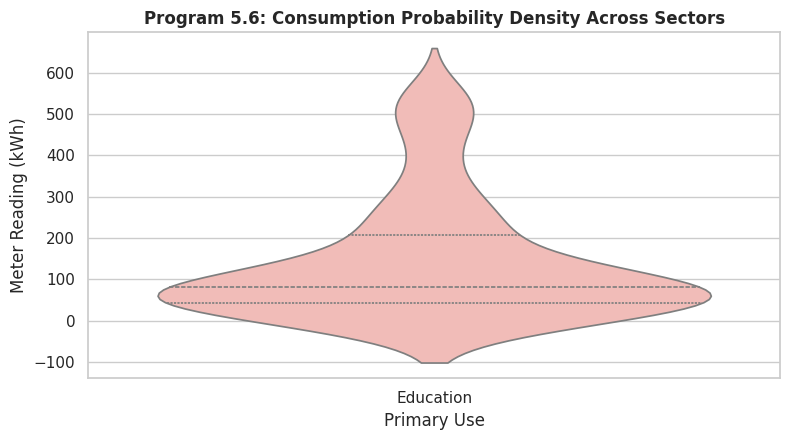

In [99]:
# ------------------------------------------------------------------------------
# Program 5.6: Categorical Distribution Density: Violin Plots
# ------------------------------------------------------------------------------
print("Rendering Program 5.6: Violin Plot...")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=df_master, x="primary_use", y="meter_reading", inner="quartile", palette="Pastel1", ax=ax)
ax.set_title("Program 5.6: Consumption Probability Density Across Sectors", weight="bold")
ax.set_xlabel("Primary Use")
ax.set_ylabel("Meter Reading (kWh)")
plt.tight_layout()
plt.show()


## Program 5.7: Multi-Facet Subplots (FacetGrid)

Rendering Program 5.7: Multi-Panel FacetGrid...


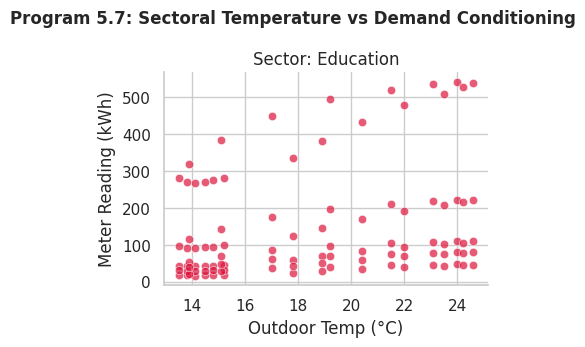

In [100]:
# ------------------------------------------------------------------------------
# Program 5.7: Multi-Facet Subplots (FacetGrid)
# ------------------------------------------------------------------------------
print("Rendering Program 5.7: Multi-Panel FacetGrid...")
g = sns.FacetGrid(df_master, col="primary_use", height=3.5, aspect=1.2, sharey=True)
g.map_dataframe(sns.scatterplot, x="air_temperature", y="meter_reading", color="crimson", alpha=0.7)
g.set_axis_labels("Outdoor Temp (°C)", "Meter Reading (kWh)")
g.set_titles(col_template="Sector: {col_name}")
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle("Program 5.7: Sectoral Temperature vs Demand Conditioning", weight="bold")
plt.show()


## Program 5.8: Temporal Aggregation: Bar Charts with Error Bars

Rendering Program 5.8: Bar Chart with Confidence Intervals...


/tmp/ipykernel_1036/1054214350.py:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(data=df_master, x="primary_use", y="meter_reading", hue="is_weekend", ci=95, palette="Blues", ax=ax)


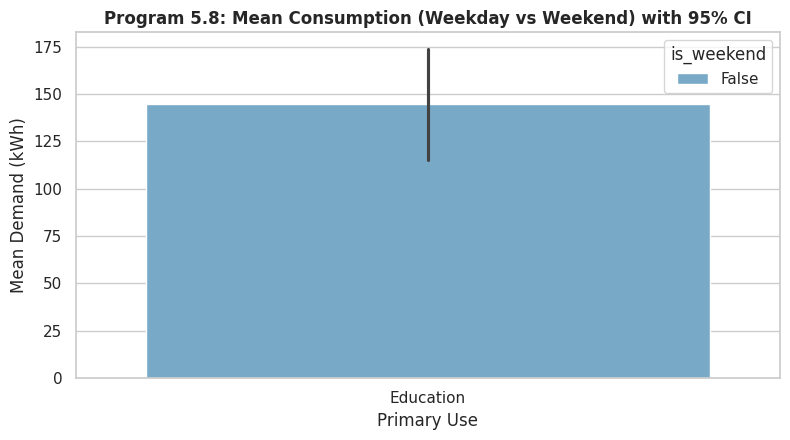

In [101]:
# ------------------------------------------------------------------------------
# Program 5.8: Temporal Aggregation: Bar Charts with Error Bars
# ------------------------------------------------------------------------------
print("Rendering Program 5.8: Bar Chart with Confidence Intervals...")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=df_master, x="primary_use", y="meter_reading", hue="is_weekend", ci=95, palette="Blues", ax=ax)
ax.set_title("Program 5.8: Mean Consumption (Weekday vs Weekend) with 95% CI", weight="bold")
ax.set_xlabel("Primary Use")
ax.set_ylabel("Mean Demand (kWh)")
plt.tight_layout()
plt.show()


## Program 5.9: Joint Bivariate Distribution (sns.jointplot)

Rendering Program 5.9: Joint Bivariate Distribution...


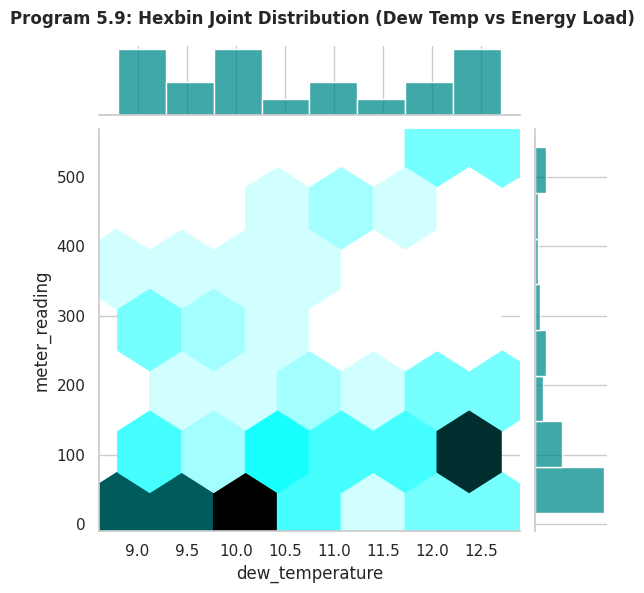

In [102]:
# ------------------------------------------------------------------------------
# Program 5.9: Joint Bivariate Distribution (sns.jointplot)
# ------------------------------------------------------------------------------
print("Rendering Program 5.9: Joint Bivariate Distribution...")
jp = sns.jointplot(data=df_master, x="dew_temperature", y="meter_reading", kind="hex", color="darkcyan", height=6)
jp.fig.subplots_adjust(top=0.92)
jp.fig.suptitle("Program 5.9: Hexbin Joint Distribution (Dew Temp vs Energy Load)", weight="bold")
plt.show()


## Program 5.10: Cumulative Multi-Building Progression Chart

Rendering Program 5.10: Cumulative Load Tracking...


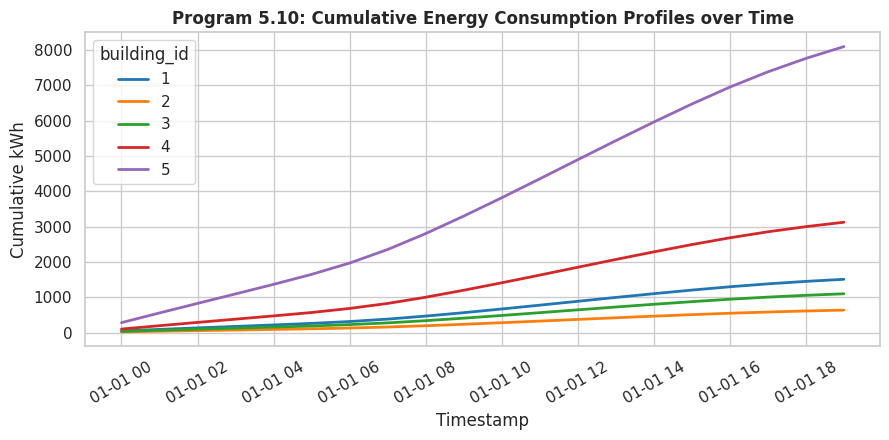


################################################################################
EXECUTION COMPLETE: All 50 programs (10 per unit) executed successfully.
################################################################################


In [103]:
# ------------------------------------------------------------------------------
# Program 5.10: Cumulative Multi-Building Progression Chart
# ------------------------------------------------------------------------------
print("Rendering Program 5.10: Cumulative Load Tracking...")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=df_master, x="timestamp", y="cumulative_building_kwh", hue="building_id",
             palette="tab10", linewidth=2, ax=ax)
ax.set_title("Program 5.10: Cumulative Energy Consumption Profiles over Time", weight="bold")
ax.set_xlabel("Timestamp")
ax.set_ylabel("Cumulative kWh")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("\n" + "#" * 80)
print("EXECUTION COMPLETE: All 50 programs (10 per unit) executed successfully.")
print("#" * 80)
